# Plot microscopic cross sections for nuclides and reactions of interest

<!-- index:description -->
Plot microscopic-cross-section pairs for nuclides and reactions of interest to fusion neutronics.
<!-- /index:description -->

<!-- generated:structure -->
```text
Plot microscopic cross sections for nuclides and reactions of interest
├── 1. Neutron multiplication
├── 2. Neutron shielding
└── 3. Common structural materials
```
<!-- /generated:structure -->

Cross sections are evaluated at 294 K, or the nearest available temperature in the nuclear-data library.

E_min in the printed results is the lowest energy with a positive calculated cross section in the sampled grid. It should not necessarily be interpreted as the precise physical reaction threshold.

In [1]:
import openmc
import pandas as pd
import matplotlib.pyplot as plt

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

pairs = pd.DataFrame([
    ('Li6',  'Li7',   '(n,2n)'),
    ('Be9',  'Pb208', '(n,2n)'),
    ('B10',  'B11',   '(n,a)'),
    ('Fe56', 'W184',  '(n,2n)'),
    ('Fe56', 'W184',  '(n,gamma)'),
], columns=['nuclide1', 'nuclide2', 'reaction'])
pairs

,nuclide1,nuclide2,reaction
0,Li6,Li7,"(n,2n)"
1,Be9,Pb208,"(n,2n)"
2,B10,B11,"(n,a)"
3,Fe56,W184,"(n,2n)"
4,Fe56,W184,"(n,gamma)"


In [2]:
def format_ax(ax):
    ax.grid()
    ax.set(
        yscale='log',
        xlabel='Energy (MeV)',
        ylabel='Microscopic cross section (b)',
    )
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))


def plot_pair(idx):
    dat = pairs.loc[idx]
    fig, ax = plt.subplots()
    logx = False

    for nuc in [dat['nuclide1'], dat['nuclide2']]:
        E, xs = openmc.plotter.calculate_cexs(
            nuc, [dat['reaction']]
        )
        E /= 1e6
        xs = xs.squeeze()

        pic = xs > 0
        E = E[pic]
        xs = xs[pic]

        if pic.any():
            print(
                '{:7s}| E_min = {:.2e} MeV | xs_max = {:.2e} b'.format(
                    nuc, E.min(), xs.max()
                )
            )
            if E.max() / E.min() > 1e10:
                logx = True
            ax.plot(E, xs, '.', ms=1, label=nuc)

    ax.set_title(dat['reaction'])
    if logx:
        ax.set_xscale('log')
    format_ax(ax)

## 1. Neutron multiplication

Li7    | E_min = 8.50e+00 MeV | xs_max = 3.23e-02 b


[('Li6', 0.07589), ('Li7', 0.92411)]

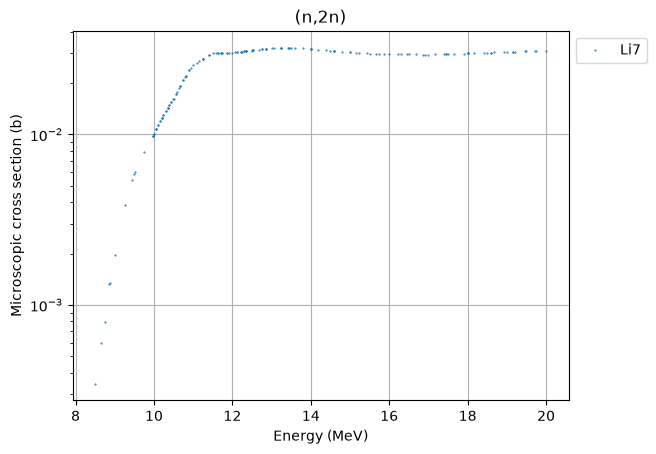

In [3]:
plot_pair(0)
openmc.data.isotopes('Li')  # natural abundance
# Li-7 has a nonzero (n,2n) cross section in the plotted data,
# while Li-6 does not.
# In terms of neutron multiplication, Li7 is better than Li6.

Be9    | E_min = 1.76e+00 MeV | xs_max = 5.59e-01 b
Pb208  | E_min = 7.50e+00 MeV | xs_max = 2.30e+00 b


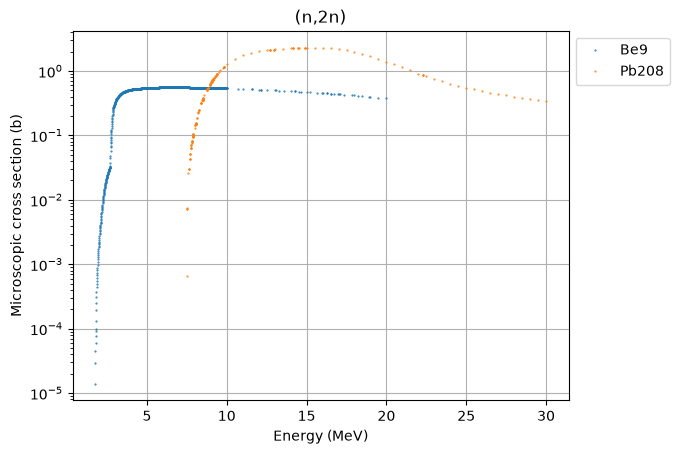

In [4]:
plot_pair(1)
# Neutron multipliers:
# energy threshold for (n,2n) is lower in Be9, but the cross
# section is higher in Pb208.

## 2. Neutron shielding

B10    | E_min = 1.00e-11 MeV | xs_max = 1.93e+05 b
B11    | E_min = 7.25e+00 MeV | xs_max = 3.30e-02 b


[('B10', 0.1982), ('B11', 0.8018)]

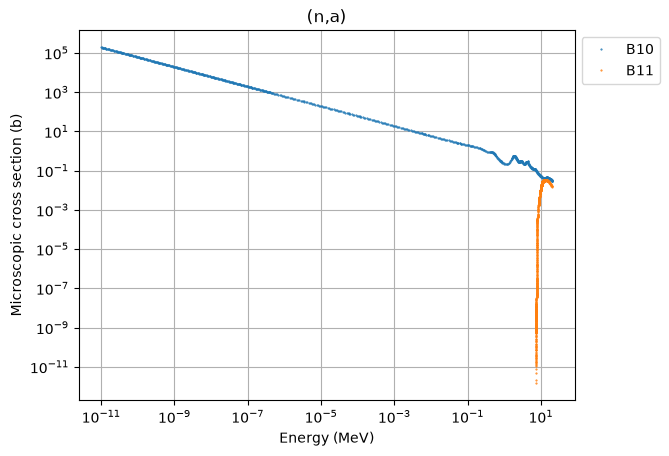

In [5]:
plot_pair(2)
openmc.data.isotopes('B')  # natural abundance
# Boron-10 (¹⁰B) is one of the best-known and most effective
# thermal-neutron absorbers, owing to its exceptionally large (n,α)
# cross section. It is widely used in neutron-shielding materials.

## 3. Common structural materials

Fe56   | E_min = 1.15e+01 MeV | xs_max = 6.34e-01 b
W184   | E_min = 7.50e+00 MeV | xs_max = 2.09e+00 b


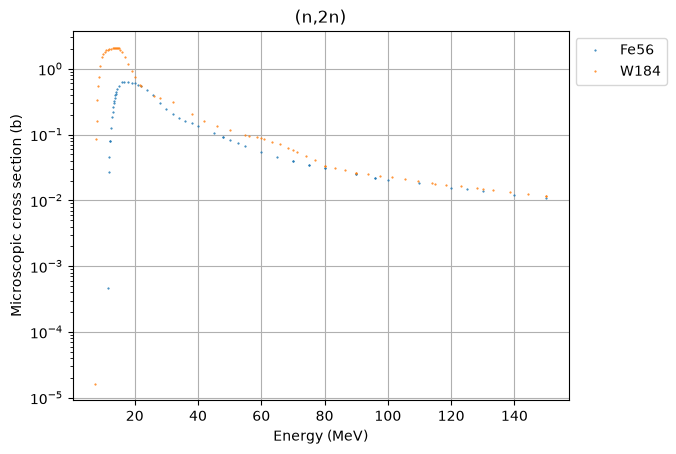

In [6]:
plot_pair(3)

Fe56   | E_min = 1.00e-11 MeV | xs_max = 1.30e+02 b
W184   | E_min = 1.00e-11 MeV | xs_max = 5.98e+02 b


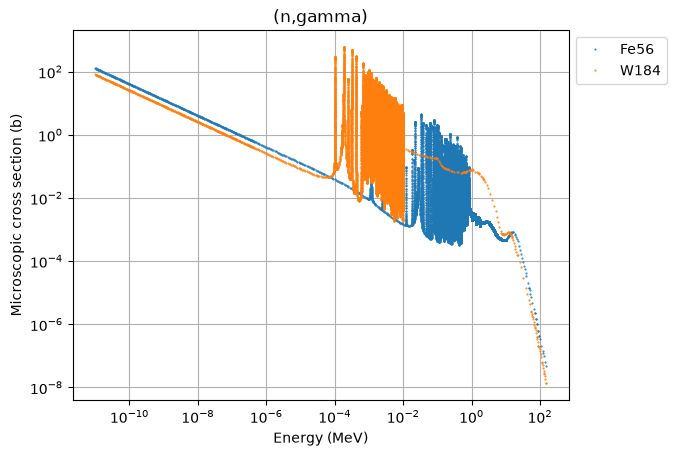

In [7]:
plot_pair(4)